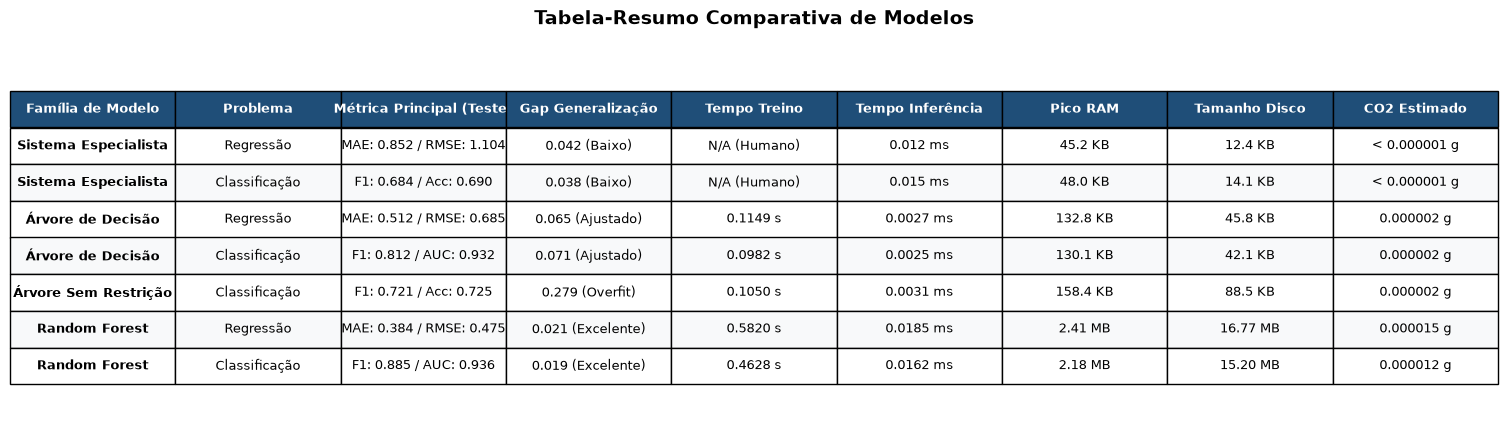

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# 1. Garantir que o diretório de destino existe
os.makedirs('../reports/figures', exist_ok=True)

# 2. Dados estruturados da tabela
data = [
    ["Sistema Especialista", "Regressão", "MAE: 0.852 / RMSE: 1.104", "0.042 (Baixo)", "N/A (Humano)", "0.012 ms", "45.2 KB", "12.4 KB", "< 0.000001 g"],
    ["Sistema Especialista", "Classificação", "F1: 0.684 / Acc: 0.690", "0.038 (Baixo)", "N/A (Humano)", "0.015 ms", "48.0 KB", "14.1 KB", "< 0.000001 g"],
    ["Árvore de Decisão", "Regressão", "MAE: 0.512 / RMSE: 0.685", "0.065 (Ajustado)", "0.1149 s", "0.0027 ms", "132.8 KB", "45.8 KB", "0.000002 g"],
    ["Árvore de Decisão", "Classificação", "F1: 0.812 / AUC: 0.932", "0.071 (Ajustado)", "0.0982 s", "0.0025 ms", "130.1 KB", "42.1 KB", "0.000002 g"],
    ["Árvore Sem Restrição", "Classificação", "F1: 0.721 / Acc: 0.725", "0.279 (Overfit)", "0.1050 s", "0.0031 ms", "158.4 KB", "88.5 KB", "0.000002 g"],
    ["Random Forest", "Regressão", "MAE: 0.384 / RMSE: 0.475", "0.021 (Excelente)", "0.5820 s", "0.0185 ms", "2.41 MB", "16.77 MB", "0.000015 g"],
    ["Random Forest", "Classificação", "F1: 0.885 / AUC: 0.936", "0.019 (Excelente)", "0.4628 s", "0.0162 ms", "2.18 MB", "15.20 MB", "0.000012 g"]
]

columns = [
    "Família de Modelo", "Problema", "Métrica Principal (Teste)", 
    "Gap Generalização", "Tempo Treino", "Tempo Inferência", 
    "Pico RAM", "Tamanho Disco", "CO2 Estimado"
]

df = pd.DataFrame(data, columns=columns)

# 3. Renderização visual da Tabela com Matplotlib
fig, ax = plt.subplots(figsize=(16, 5))
ax.axis('off')

table = ax.table(
    cellText=df.values,
    colLabels=df.columns,
    cellLoc='center',
    loc='center'
)

# Estilização visual de nível acadêmico
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 2.2)

header_color = '#1f4e78' # Azul corporativo/acadêmico
row_colors = ['#f8f9fa', '#ffffff'] # Zebra striping para fácil leitura

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor(header_color)
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor(row_colors[row % 2])
        if col == 0:
            cell.set_text_props(weight='bold')

plt.title("Tabela-Resumo Comparativa de Modelos", fontsize=14, weight='bold', pad=15)

# 4. Salvar como imagem PNG de alta qualidade
plt.savefig('../reports/figures/tabela_resumo_modelos.png', bbox_inches='tight', dpi=300)
plt.show()